# Task 2.4: A better readout

**Method.** (a) Simulate the real circuit without approximations. (b) Measure how bit flips grow with drive strength. (c, d) Compare pulse shapes and optimize one with gradients through the simulator.

In [1]:
import sys, json, glob
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
S2 = ROOT / 'results/s2'
load = lambda pat: [json.loads(Path(f).read_text()) for f in sorted(glob.glob(str(S2 / pat)))]
show = lambda name, w=750: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))
sys.path.insert(0, str(ROOT))
from research.s2.common import KAPPA_A
nominal = lambda d: d['eps_z_over_g2'] == 0 and d['n_th'] == 0 and d['kappa_a'] == KAPPA_A and abs(d['kappa_b'] - 16.3363) < 1e-3

def largest(rows):
    best = {}
    for d in rows:
        k = round(d['alpha'], 2)
        if k not in best or d['na'] * d['nb'] > best[k]['na'] * best[k]['nb']:
            best[k] = d
    return best

In [2]:
ps = load('pulse_a2.10_30x8_T2_peak.json')[0]
from math import erfc, sqrt
err = lambda r: 0.5 * erfc(sqrt(r['snr'] / 2)) + r['p_flip']        # misread + flipped by the readout
names = {'square': 'square', 'bang': 'bang-bang resonant', 'res': 'resonant cosine'}
pd.DataFrame([{'pulse': names[f], 'best peak (× g2)': r['level'], 'signal (SNR)': round(r['snr'], 1),
               'bit flip prob.': f"{r['p_flip']:.1e}", 'readout error': f"{100 * err(r):.2f}%"}
              for f in names for r in [min((r for r in ps['rows'] if r['family'] == f), key=err)]])

,pulse,best peak (× g2),signal (SNR),bit flip prob.,readout error
0,square,1.00,7.5,8.1e-03,1.12%
1,bang-bang resonant,0.75,12.8,9.2e-03,0.94%
2,resonant cosine,0.75,8.2,4.4e-03,0.65%


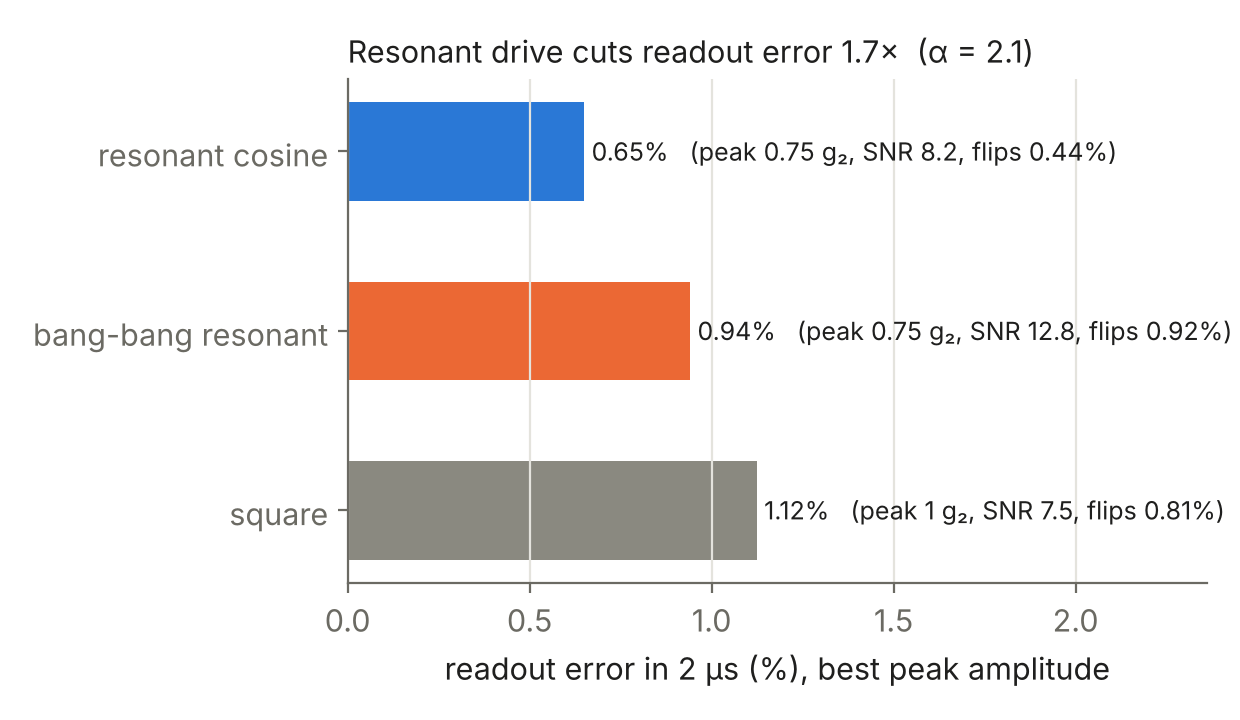

In [3]:
show('slide_readout_error', 650)

In [4]:
opt = [d for d in load('opt_*.json') if not d.get('partial') and d['nb'] >= 8]   # converged truncations only
pd.DataFrame([{'alpha': d['alpha'], 'window (µs)': d['T'], 'peak (× g2)': d['peak'],
               'signal vs square': round(d['best']['snr'] / d['square']['snr'], 2),
               'flips vs square': round(d['best']['p_flip'] / d['square']['p_flip'], 2),
               'signal per flip vs square': round(d['best']['ratio_vs_square'], 2)}
              for d in sorted(opt, key=lambda d: (d['alpha'], d['T'], d['peak']))])

,alpha,window (µs),peak (× g2),signal vs square,flips vs square,signal per flip vs square
0,1.4,0.5,0.5,0.89,0.58,1.55
1,1.4,0.5,1.0,0.94,0.57,1.66
2,1.4,1.0,0.5,1.13,0.71,1.59
3,1.8,0.5,0.5,1.27,0.93,1.36
4,1.8,0.5,1.0,1.13,0.66,1.71
5,1.8,1.0,0.5,1.88,1.42,1.32
6,2.1,0.5,0.5,1.51,1.20,1.26
7,2.1,0.5,1.0,1.40,0.90,1.56
8,2.1,1.0,0.5,1.71,1.31,1.30


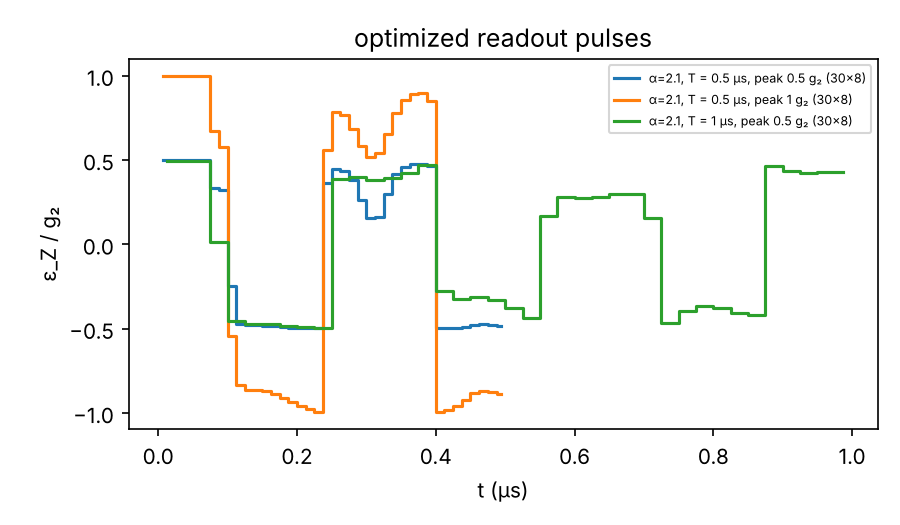

In [5]:
show('optimized_pulses', 650)

**Result.**
- (a) The pump must be **retuned by −23 MHz**; at the nominal frequency, Stark shifts stop the photon pairing.
- (b) Signal and extra flips both grow as drive², so turning up the drive doesn't help. Only the pulse **shape** does.
- (c, d) Driving at the 3.2 MHz ringing frequency cuts readout error **1.7×** (1.12% → 0.65%). The gradient-optimized pulse gives **1.3–1.7× more signal per bit flip** than a square pulse in all 9 converged settings.